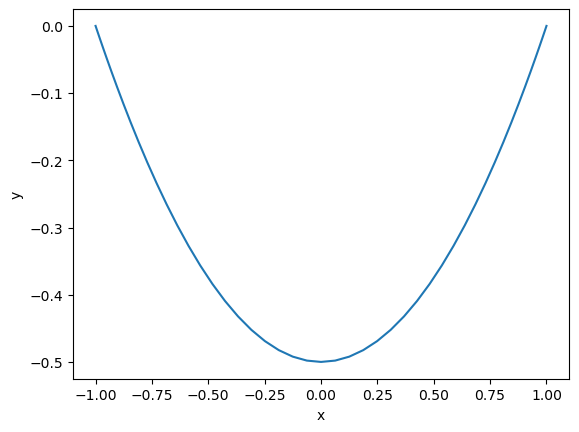

In [9]:
import numpy as np
from matplotlib import pyplot as plt

#Sample non homogenous ODE: d^2y/dx^2=1, y(1)=y(-1)=0

# Collocation Points
def colpts(N):
    x=np.zeros(N+1)
    for i in range(N+1):
        x[i]=np.cos(np.pi*i/N)
    return x

#Derivative Matrix
def DMat(N):
    z=colpts(N)
    D=np.ones((N+1, N+1))
    c=np.ones(N+1)
    c[0]=2
    c[N]=2
    for i in range(N+1):
        for j in range(N+1):
            if i==0 and j==0:
                D[i][j]=(2*(N**2)+1)/6
            elif i==N and j==N:
                D[i][j]=-(2*(N**2)+1)/6
            elif i==j and i!=0 and i!=N:
                D[i][j]=-1* z[i]/(2*(1-z[i]**2))
            else:
                D[i][j]=(c[i]/c[j])*((-1)**(i+j)/(z[i]-z[j]))
    return D

N=50 #Number of points where we are applying Derivatives
x=colpts(N)
D=DMat(N)
D2=np.dot(D, D)

f=np.ones(N+1)

#x=1 (the 0th row): y=0
D2[0, :]=0
D2[0, 0]=1
f[0]=0

#x=-1 (the N th row): y=0
D2[N, :]=0
D2[N, N]=1
f[N]=0

y=np.linalg.solve(D2, f)
plt.plot(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.show()

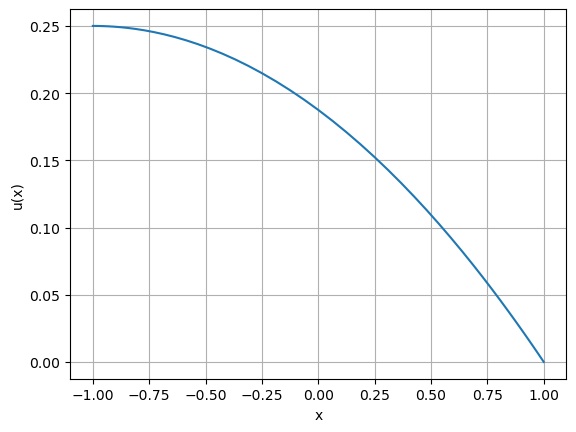

In [71]:
#A simpler case:
import numpy as np
from matplotlib import pyplot as plt

#Collocation Points
def colpts(N):
    x=np.zeros(N+1)
    for i in range(N+1):
        x[i]=np.cos(np.pi*i/N)
    return x

#Derivative Matrix
def DMat(N):
    z=colpts(N)
    D=np.ones((N+1, N+1))
    c=np.ones(N+1)
    c[0]=2
    c[N]=2
    for i in range(N+1):
        for j in range(N+1):
            if i==0 and j==0:
                D[i][j]=(2*(N**2)+1)/6
            elif i==N and j==N:
                D[i][j]=-(2*(N**2)+1)/6
            elif i==j and i!=0 and i!=N:
                D[i][j]=-1* z[i]/(2*(1-z[i]**2))
            else:
                D[i][j]=(c[i]/c[j])*((-1)**(i+j)/(z[i]-z[j]))
    return D

#Main Solution Part
def soln(N, H):
    M0=np.zeros((N+1, N+1))
    x=colpts(N)

    D1=(2/H)*DMat(N)
    D2=np.dot(D1, D1)
    
    #Now incorporate the BCs into these matrices
    rc=(H/2)*(x+1)
    r=np.diag(rc)
    
    A=np.dot(r, D2)+D1
    B=-rc
    
    A[0, :]=0
    A[0, 0]=1
    B[0]=0

    A[N, :]=0
    A[N, :]=D1[N, :]
    B[N]=0
    S=np.linalg.solve(A, B)
    return S, x

s1, _ = soln(50, 1)
_, x = soln(50, 1)
x1=1/2*(x+1)
plt.plot(x, s1)
plt.xlabel("x")
plt.ylabel("u(x)")
plt.grid(True)
plt.show()

[0.16913283]


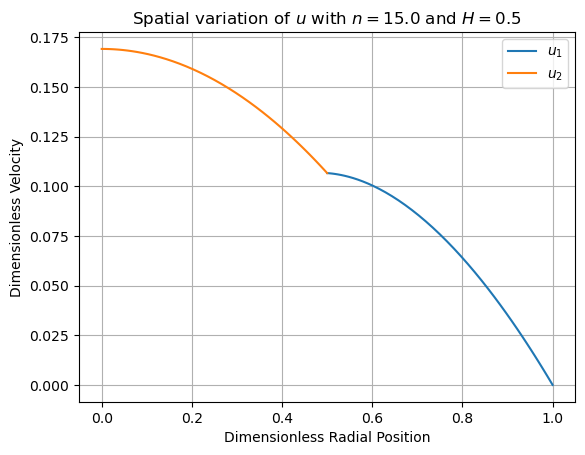

In [193]:
import numpy as np
from matplotlib import pyplot as plt

#Collocation Points
def colpts(N):
    x=np.zeros(N+1)
    for i in range(N+1):
        x[i]=np.cos(np.pi*i/N)
    return x

#Derivative Matrix
def DMat(N):
    z=colpts(N)
    D=np.ones((N+1, N+1))
    c=np.ones(N+1)
    c[0]=2
    c[N]=2
    for i in range(N+1):
        for j in range(N+1):
            if i==0 and j==0:
                D[i][j]=(2*(N**2)+1)/6
            elif i==N and j==N:
                D[i][j]=-(2*(N**2)+1)/6
            elif i==j and i!=0 and i!=N:
                D[i][j]=-1* z[i]/(2*(1-z[i]**2))
            else:
                D[i][j]=(c[i]/c[j])*((-1)**(i+j)/(z[i]-z[j]))
    return D

#Main Solution Part
#In the code
def soln(N, H, K, n):
    M0=np.zeros((N+1, N+1))
    M00=np.zeros(N+1)
    I=np.ones((2*(N+1), 2*(N+1)))
    x=colpts(N)

    D1_d=(-2/H)*DMat(N)
    D2_d=np.dot(D1_d, D1_d)
    rd=(H/2)*(1-x)
    r2=np.diag(rd)
    b2=(K*rd).reshape(-1, 1)
    
    D1_c=(2/(1-H))*DMat(N)
    D2_c=np.dot(D1_c, D1_c)
    rc=1+0.5*(1-H)*(x-1)
    r1=np.diag(rc)
    b1=(K * rc).reshape(-1, 1)
    
    #Big D Matrices
    R1=np.dot(r1, D2_c)+D1_c
    R2=np.dot(r2, D2_d)+D1_d
    A1=np.hstack((R1, M0))
    A2=np.hstack((M0, R2))
    A=np.vstack((A1, A2))
    B=np.vstack((b1, b2))
    #print(B)

    #Now incorporate the BCs into these matrices
    #BC1: u1(R)=0
    A[0, :]=0
    A[0, 0]=1
    B[0]=0

    #BC2: u1=u2 @ R_d
    A[N, :]=0
    A[N, N]=1
    A[N, 2*N+1]=-1
    B[N]=0

    #BC3: du2/dr=0
    A[N+1, :]=np.hstack((M00, D1_d[0, :]))
    B[N+1]=0

    #BC4: tau1=tau2
    A[2*N+1, :]=n*np.hstack((D1_c[N, :], M00))-np.hstack((M00, D1_d[N, :]))
    B[2*N+1]=0

    S=np.linalg.solve(A, B)
    z1=rc.reshape(-1, 1)
    z2=rd.reshape(-1, 1)
    z=np.vstack((z1, z2))
    return S, z
H=0.5
n=15.0
N=50
S1, x1=soln(N, H, -1, n)
u1 = S1[:N+1]  # u1 on rc (r in [H, 1])
u2 = S1[N+1:]  # u2 on rd (r in [0, H])
rc = x1[:N+1].flatten()
rd = x1[N+1:].flatten()
print(u2[0])
plt.plot(rc, u1, label='$u_1$')
plt.plot(rd, u2, label='$u_2$')
plt.xlabel('Dimensionless Radial Position')
plt.ylabel('Dimensionless Velocity')
plt.title(f'Spatial variation of $u$ with $n={n}$ and $H={H}$')
plt.legend()
plt.grid(True)
plt.show()
